In [1]:
# Global Imports and Runtime Visual Configuration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual styling settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print("Global libraries for automated EDA and profiling loaded successfully.")

Global libraries for automated EDA and profiling loaded successfully.


### 1.Comprehensive Profiling with YData-Profiling / Sweetviz

                mean           std           min            max
age        43.425000     14.941910     18.000000      69.000000
income  59991.120320  15861.535777  16808.146598  107805.500071
score       0.513444      0.286941      0.013672       0.995931


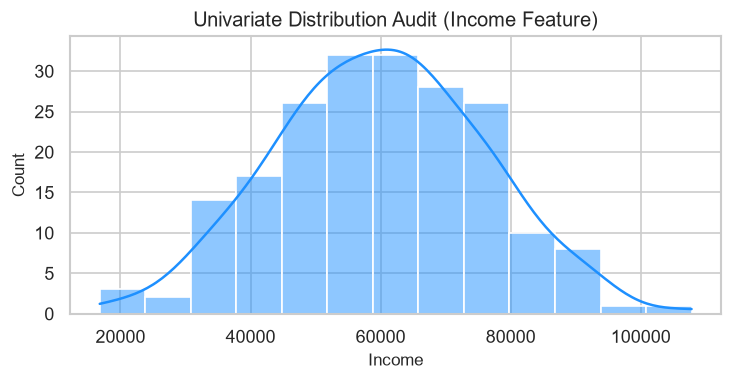

In [10]:
np.random.seed(42)
df_eda = pd.DataFrame({
    'age': np.random.randint(18, 70, 200),
    'income': np.random.normal(60000, 15000, 200),
    'score': np.random.rand(200)
})

profile_summary = df_eda.describe().T[['mean', 'std', 'min', 'max']]
print(profile_summary)

#Visualization: Distribution overview
plt.figure(figsize=(7,3))
sns.histplot(df_eda['income'], kde=True, color='dodgerblue') # kde : Kernel Density Estimate, shows the smoothed distribution of the data
plt.title('Univariate Distribution Audit (Income Feature)')
plt.xlabel('Income')
plt.show()

In [ ]:
# %pip install --force-reinstall "setuptools==80.9.0"
# %pip uninstall -y numpy
# %pip install numpy==2.3.5
# %pip show numpy
# %pip install --no-cache-dir numpy==2.3.5

   ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
   ------ --------------------------------- 2.1/12.8 MB 9.5 MB/s eta 0:00:02
   ------------- -------------------------- 4.2/12.8 MB 9.5 MB/s eta 0:00:01
   -------------------- ------------------- 6.6/12.8 MB 10.2 MB/s eta 0:00:01
   ------------------------------- -------- 10.0/12.8 MB 11.5 MB/s eta 0:00:01
   -------------------------------------- - 12.3/12.8 MB 11.6 MB/s eta 0:00:01
   ---------------------------------------- 12.8/12.8 MB 11.6 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


ERROR: Could not install packages due to an OSError: [WinError 5] Access is denied: 'd:\\Data_Analytics\\my_practise\\cdacvenv\\Lib\\site-packages\\numpy\\linalg\\_umath_linalg.cp313-win_amd64.pyd'
Check the permissions.


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
# import sys
# import numpy as np
# import importlib.metadata as metadata

# print("Python:", sys.executable)
# print("NumPy loaded:", np.__version__)

# try:
#     print("NumPy installed:", metadata.version("numpy"))
# except metadata.PackageNotFoundError:
#     print("NumPy package metadata is missing")

Python: d:\Data_Analytics\my_practise\cdacvenv\Scripts\python.exe
NumPy loaded: 2.5.4
NumPy package metadata is missing


In [3]:
import sweetviz as sv
np.random.seed(42)
df_eda = pd.DataFrame({
    'age': np.random.randint(18, 70, 200),
    'income': np.random.normal(60000, 15000, 200),
    'score': np.random.rand(200)
})
report = sv.analyze(df_eda)
report.show_html("sweetviz_report.html")

Done! Use 'show' commands to display/save.   |██████████| [100%]   00:00 -> (00:00 left)


Report sweetviz_report.html was generated! NOTEBOOK/COLAB USERS: the web browser MAY not pop up, regardless, the report IS saved in your notebook/colab files.


### 2. Automated Quality and Integrity Audits

In [7]:
df_audit = pd.DataFrame({
    'id': [1, 2, 2, 4, 5],
    'status': ['Active', 'Pending', 'Pending', 'Closed', None],
    'amount': [100, 200, 200, -50, 500]
})
print(df_audit)
null_counts = df_audit.isna().sum()
duplicate_counts = df_audit.duplicated().sum()
print("Null counts per column:\n", null_counts)
print("Number of duplicate rows:", duplicate_counts)

   id   status  amount
0   1   Active     100
1   2  Pending     200
2   2  Pending     200
3   4   Closed     -50
4   5     None     500
Null counts per column:
 id        0
status    1
amount    0
dtype: int64
Number of duplicate rows: 1


### 3. Data Schema Validation with Pandas-Schema

Validation errors: ['Age cannot be negative']
Status counts: [np.int64(3), np.int64(1)]


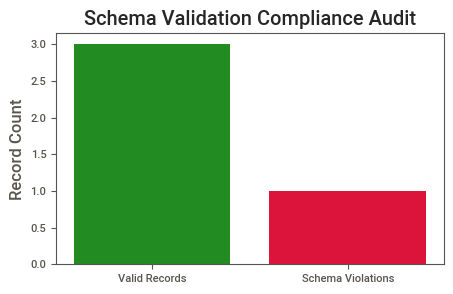

In [11]:
# Custom schema validation function simulation
def validate_schema(df):
    errors = []
    if not pd.api.types.is_integer_dtype(df['age']):
        errors.append('Age must be an Integer')
    if (df['age'] < 0 ).any():
        errors.append('Age cannot be negative')
    return errors;

df_test = pd.DataFrame({'age': [25, 30, -5, 67]})
validation_errors = validate_schema(df_test)
print("Validation errors:", validation_errors)
proper_age_count = (df_test['age'] >= 0).sum()
improper_age_count = (df_test['age'] < 0).sum()
status_counts = [proper_age_count, improper_age_count]

print("Status counts:", status_counts)

plt.figure(figsize=(5, 3))
plt.bar(['Valid Records', 'Schema Violations'], status_counts, color=['forestgreen', 'crimson'])
plt.ylabel('Record Count')
plt.title('Schema Validation Compliance Audit')
plt.show()

### 4.Dataset Overview Summaries

In [ ]:
df_overview = pd.DataFrame({
    'col_int': [1, 2, 3],
    'col_float': [1.1, 2.2, 3.3],
    'col_str': ['A', 'B', 'C']
})

dtype_counts = df_overview.dtypes.value_counts()
print("Data type counts:\n", dtype_counts)

# df_overview.dtypes tells you the data type of each column.

Data type counts:
 int64      1
float64    1
object     1
Name: count, dtype: int64
